# Semana 11 — Diseño de experimentos e hipótesis

**Objetivo:** escribir el plan **antes** de correr el experimento, con una predicción
cuantitativa que el resultado pueda refutar.

## Pregunta e hipótesis

*¿Cómo afecta una corriente constante a la frecuencia de disparo del LIF de la semana 3?*

- **H1 (cuantitativa):** no hay spikes por debajo de la reobase
  $I_\text{rh} = (V_\text{th} - V_\text{rest})/R = 1.5$ nA, y por encima la frecuencia sigue
  $f(I) = \big[t_\text{ref} + \tau_m \ln\frac{RI}{RI - 15\,\text{mV}}\big]^{-1}$.
- **Explicación alternativa:** un desacuerdo puede venir de la ventana de observación finita
  (300 ms solo permite frecuencias múltiplos de 3.3 Hz) o del paso temporal, no del modelo.

## Plan (fijado antes de ejecutar)

| Elemento | Decisión |
|---|---|
| Variable independiente | corriente de 0 a 3 nA, 16 niveles equiespaciados |
| Observable | spikes en 300 ms / 0.3 s |
| Criterio de éxito | 0 spikes para $I < 1.5$ nA y error ≤ 1 spike (3.3 Hz) respecto a la teoría |
| Supuestos | una neurona LIF determinista, sin ruido ni entrada sináptica |

El plan se guarda como `experiment_plan.md` junto con los resultados.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from computational_neuroscience import lif_firing_rate, simulate_lif
from computational_neuroscience.outputs import save_data, save_figure, save_text

WEEK = 11
WINDOW_S = 0.3
RHEOBASE_NA = 1.5
currents = np.linspace(0.0, 3.0, 16)

plan = """# Week 11 experiment plan

## Question
How does constant injected current affect the firing rate of the LIF model?

## Hypothesis (written before running)
No spikes below rheobase (1.5 nA). Above it, the rate follows the analytic LIF f-I curve.

## Independent variable
Injected current from 0 to 3 nA in 16 equally spaced steps.

## Outcome
Spike count in a 300 ms window divided by 0.3 s.

## Success criterion
Zero spikes below 1.5 nA, and |simulated count - predicted count| <= 1 spike above it.

## Assumptions
One deterministic LIF neuron, fixed parameters, no synaptic input or noise.

## Alternative explanation
Disagreement may come from the finite 300 ms window or the time step, not the model.
"""
save_text(WEEK, "experiment_plan.md", plan)

Saved: weeks/week_11_experiment_design/outputs/experiment_plan.md


In [2]:
counts = np.array([simulate_lif(current, duration_ms=WINDOW_S * 1000).spike_times_ms.size for current in currents])
rates = counts / WINDOW_S
predicted = lif_firing_rate(currents)

## Figura

Puntos: frecuencias observadas en la ventana de 300 ms. Línea: predicción teórica (escrita en
el plan). La resolución de la ventana es $1/0.3\,\text{s} \approx 3.3$ Hz, de ahí los escalones.

Saved: weeks/week_11_experiment_design/outputs/current_sweep.png
Saved: weeks/week_11_experiment_design/outputs/current_sweep.npz


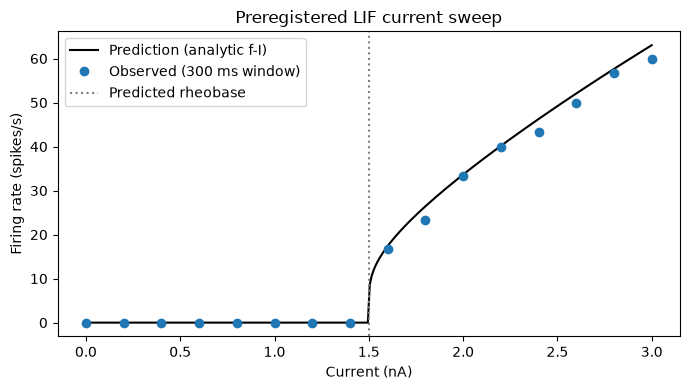

In [3]:
fine = np.linspace(0.0, 3.0, 300)
figure, axis = plt.subplots(figsize=(7, 4))
axis.plot(fine, lif_firing_rate(fine), "k-", label="Prediction (analytic f-I)")
axis.plot(currents, rates, "o", label="Observed (300 ms window)")
axis.axvline(RHEOBASE_NA, color="grey", linestyle=":", label="Predicted rheobase")
axis.set(xlabel="Current (nA)", ylabel="Firing rate (spikes/s)", title="Preregistered LIF current sweep")
axis.legend()
save_figure(WEEK, figure, "current_sweep.png")
save_data(WEEK, "current_sweep.npz", current_na=currents, firing_rate_hz=rates, predicted_rate_hz=predicted)

## Validación (criterio de éxito del plan)

In [4]:
below = currents < RHEOBASE_NA
assert np.all(counts[below] == 0)
count_error = np.abs(counts[~below] - predicted[~below] * WINDOW_S)
assert count_error.max() <= 1.0, count_error.max()
first_spiking = currents[np.argmax(counts > 0)]
print(f"First tested current with spikes: {first_spiking:.1f} nA (predicted rheobase {RHEOBASE_NA} nA)")
print(f"Max count error above rheobase: {count_error.max():.2f} spikes -> hypothesis not refuted")

First tested current with spikes: 1.6 nA (predicted rheobase 1.5 nA)
Max count error above rheobase: 0.93 spikes -> hypothesis not refuted


## Interpretación y límites

- El resultado **no refuta** H1; eso no la "prueba": solo se probaron 16 corrientes y una
  configuración de parámetros.
- La reobase estimada (primer nivel con spikes, 1.6 nA) depende de la rejilla; para medirla mejor
  habría que refinar los niveles cerca de 1.5 nA.

**Para tu entrega:** escribe un plan propio (pregunta, H1, alternativa, criterio de éxito)
sobre otro modelo y ejecútalo solo después de guardarlo.